In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import ( accuracy_score, mean_absolute_error,mean_squared_error,r2_score,precision_score,recall_score,f1_score,confusion_matrix,ConfusionMatrixDisplay,classification_report)
from sklearn.linear_model import LogisticRegression, LinearRegression

np.random.seed(7)

In [2]:
ecommerce = pd.read_csv("ecommerce_churn_cleaned.csv")

In [3]:
print(ecommerce.shape)
print(ecommerce.isnull().sum())
ecommerce.describe

(120, 10)
customer_id             0
age                     0
annual_income           0
tenure_months           0
monthly_spend           0
support_calls           0
orders_last_6_months    0
contract_type           0
region                  0
churn                   0
dtype: int64


<bound method NDFrame.describe of      customer_id   age  annual_income  tenure_months  monthly_spend  \
0           2001  34.0       470994.0           49.0        36974.0   
1           2002  41.0       372922.0           14.0        25882.0   
2           2003  44.0       143257.0           15.0        32210.0   
3           2004  28.0       236419.0           31.0        28136.0   
4           2005  27.0       394022.0            1.0        15709.0   
..           ...   ...            ...            ...            ...   
115         2116  54.0       281133.0           16.0        41597.0   
116         2117  52.0       288791.0            8.0        11252.0   
117         2118  45.0       210429.0            4.0        36972.0   
118         2119  60.0       282206.0            4.0        34181.0   
119         2120  21.0       324820.0           56.0         6944.0   

     support_calls  orders_last_6_months contract_type         region  churn  
0              1.0                

In [4]:
ecommerce

,customer_id,age,annual_income,tenure_months,monthly_spend,support_calls,orders_last_6_months,contract_type,region,churn
0,2001,34.0,470994.0,49.0,36974.0,1.0,5.0,Monthly,Abuja,0
1,2002,41.0,372922.0,14.0,25882.0,4.0,4.0,Annual,Port Harcourt,0
2,2003,44.0,143257.0,15.0,32210.0,4.0,8.0,Quarterly,Lagos,0
3,2004,28.0,236419.0,31.0,28136.0,5.0,14.0,Quarterly,Lagos,0
4,2005,27.0,394022.0,1.0,15709.0,3.0,4.0,Monthly,Lagos,0
...,...,...,...,...,...,...,...,...,...,...
115,2116,54.0,281133.0,16.0,41597.0,3.0,4.0,Annual,Lagos,0
116,2117,52.0,288791.0,8.0,11252.0,7.0,7.0,Annual,Port Harcourt,0
117,2118,45.0,210429.0,4.0,36972.0,5.0,9.0,Monthly,Lagos,0
118,2119,60.0,282206.0,4.0,34181.0,2.0,4.0,Annual,Port Harcourt,0


In [5]:
ecommerce.columns

Index(['customer_id', 'age', 'annual_income', 'tenure_months', 'monthly_spend',
       'support_calls', 'orders_last_6_months', 'contract_type', 'region',
       'churn'],
      dtype='str')

In [6]:
ecommerce_encoded = pd.get_dummies(ecommerce, columns=["contract_type", "region"], drop_first=True)

In [7]:
print(ecommerce_encoded.columns)

Index(['customer_id', 'age', 'annual_income', 'tenure_months', 'monthly_spend',
       'support_calls', 'orders_last_6_months', 'churn',
       'contract_type_Monthly', 'contract_type_Quarterly',
       'contract_type_unknown', 'region_Enugu', 'region_Ibadan',
       'region_Lagos', 'region_Port Harcourt'],
      dtype='str')


In [8]:
# numeric_features = [["age", "annual_income", "tenure_months", "monthly_spend", "support_calls", "orders_last_6_months", "region_Lagos", "region_Enugu", "region_Port Harcourt", "region_Ibadan", "contract_type_Monthly", "contract_type_Quarterly"]]
X = ecommerce_encoded.drop(columns=["churn"])
Y = ecommerce_encoded["churn"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X,Y, test_size=0.2, random_state=42, stratify=Y
)

print("Train: ", X_train.shape, "Test:", X_test.shape)

Train:  (96, 14) Test: (24, 14)


In [9]:
log_model = make_pipeline(StandardScaler(), LogisticRegression())
log_model.fit(X_train, Y_train)

log_pred = log_model.predict(X_test)
print("Logistic Regression accuracy:", round(accuracy_score(Y_test, log_pred), 3))

Logistic Regression accuracy: 0.875


In [10]:
cm = confusion_matrix(Y_test, log_pred)
print(cm)



[[18  1]
 [ 2  3]]


The Breakdown
Remember: 0 = Stayed, 1 = Churned.
Test set has 24 people. The matrix is read like this:

Top-Left (18) = True Negatives

The model predicted Stay (0), and they actually stayed.

Verdict: 18 correct "Stay" predictions.

Top-Right (1) = False Positives

The model predicted Churn (1), but they actually stayed.

Verdict: 1 false alarm. The company might waste a discount on this person. 

Bottom-Left (2) = False Negatives

The model predicted Stay (0), but they actually churned.

Verdict: The model missed 2 people who left. This is usually the most expensive mistake for a business. 

Bottom-Right (3) = True Positives

The model predicted Churn (1), and they actually churned.

Verdict: 3 correct "Churn" predictions. This is the money-maker

In [11]:
print(f"Accuracy : {accuracy_score(Y_test, log_pred):.2f}")
print(f"Precison : {precision_score(Y_test, log_pred):.2f}")
print(f"Recall : {recall_score(Y_test, log_pred):.2f}")
print(f"F1-score : {f1_score(Y_test, log_pred):.2f}")

Accuracy : 0.88
Precison : 0.75
Recall : 0.60
F1-score : 0.67


In [12]:
X_train.columns

Index(['customer_id', 'age', 'annual_income', 'tenure_months', 'monthly_spend',
       'support_calls', 'orders_last_6_months', 'contract_type_Monthly',
       'contract_type_Quarterly', 'contract_type_unknown', 'region_Enugu',
       'region_Ibadan', 'region_Lagos', 'region_Port Harcourt'],
      dtype='str')

In [13]:
#predict for a new customer
customer = pd.DataFrame({"customer_id": [2500],"age": [20.0], "annual_income": [500000.0], "tenure_months": [5.0], "monthly_spend": [6000.0], "support_calls": [1.0], "orders_last_6_months": [30.0],  "contract_type_Monthly": [1], "contract_type_Quarterly": [0], "contract_type_unknown": [0], "region_Enugu": [1], "region_Ibadan": [0], "region_Lagos": [0], "region_Port Harcourt": [0], })

print("predicted churn:", log_model.predict(customer)[0], "(1 = churn, 0 = stay)")
proba = log_model.predict_proba(customer)[0]
print(f"Probability of staying: {proba[0]:.2f}")
print(f"Probability of churning: {proba[1]:.2f}")


predicted churn: 1 (1 = churn, 0 = stay)
Probability of staying: 0.40
Probability of churning: 0.60


In [14]:
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42) 
tree_model.fit(X_train, Y_train)

tree_pred = tree_model.predict(X_test)
print("Decision tree accuracy: ", round(accuracy_score(Y_test, tree_pred), 3))

Decision tree accuracy:  0.625


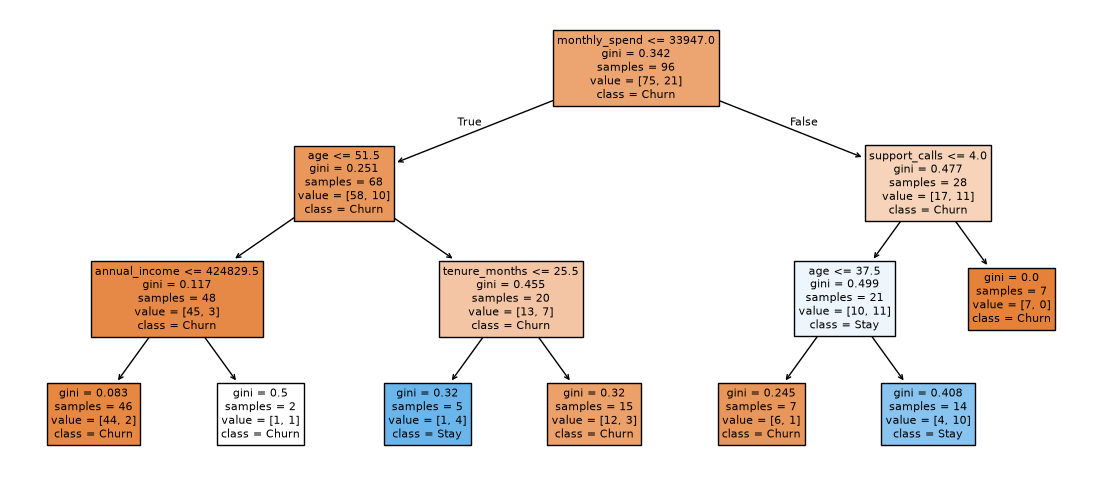

In [15]:
plt.figure(figsize=(14,6))
plot_tree(tree_model, feature_names=X.columns, class_names=["Churn", "Stay"], filled=True, rounded=False)
plt.show()

In [16]:
cm = confusion_matrix(Y_test, tree_pred)
print(cm)

[[14  5]
 [ 4  1]]


In [17]:
print(f"Accuracy : {accuracy_score(Y_test, tree_pred):.2f}")
print(f"Precison : {precision_score(Y_test, tree_pred):.2f}")
print(f"Recall : {recall_score(Y_test, tree_pred):.2f}")
print(f"F1-score : {f1_score(Y_test, tree_pred):.2f}")

Accuracy : 0.62
Precison : 0.17
Recall : 0.20
F1-score : 0.18
